# LAB 4: Tiền xử lý dữ liệu (P1)

**Học phần:** Dữ liệu lớn (Big Data)  
**Mã số sinh viên:** 26410022

Bài gồm (I) truy xuất và khám phá Moneyball từ OpenML, điền giá trị thiếu bằng trung vị rồi so sánh mô hình hồi quy; (II) kiểm tra, xử lý dữ liệu thiếu và phân bố `rating` của Netflix 2019.

## I. Moneyball: truy xuất và tìm dữ liệu thiếu

Nguồn: [OpenML dataset 41021](https://www.openml.org/d/41021), biến mục tiêu `RS` (runs scored). Notebook ưu tiên bản CSV trong repo; khi chạy trên Colab sẽ tải trực tiếp từ OpenML qua `fetch_openml`, nên không cần cài thêm gói `openml`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from pandas.plotting import scatter_matrix
from sklearn.datasets import fetch_openml
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

moneyball_paths = [Path("datasets/lab4/moneyball.csv"), Path("../datasets/lab4/moneyball.csv")]
moneyball_path = next((p for p in moneyball_paths if p.is_file()), None)
if moneyball_path:
    moneyball = pd.read_csv(moneyball_path)
    print("Nguồn:", moneyball_path)
else:
    moneyball = fetch_openml(data_id=41021, as_frame=True).frame
    print("Nguồn: OpenML dataset 41021")
print("Kích thước:", moneyball.shape)
display(moneyball.head())

Nguồn: datasets/lab4/moneyball.csv
Kích thước: (1232, 15)


,Team,League,Year,RS,RA,W,OBP,SLG,BA,Playoffs,RankSeason,RankPlayoffs,G,OOBP,OSLG
0,ARI,NL,2012,734,688,81,0.328,0.418,0.259,0,NaN,NaN,162,0.317,0.415
1,ATL,NL,2012,700,600,94,0.320,0.389,0.247,1,4.0,5.0,162,0.306,0.378
2,BAL,AL,2012,712,705,93,0.311,0.417,0.247,1,5.0,4.0,162,0.315,0.403
3,BOS,AL,2012,734,806,69,0.315,0.415,0.260,0,NaN,NaN,162,0.331,0.428
4,CHC,NL,2012,613,759,61,0.302,0.378,0.240,0,NaN,NaN,162,0.335,0.424


In [2]:
missing_moneyball = moneyball.isna().sum().sort_values(ascending=False)
print("Số giá trị thiếu theo cột:")
display(missing_moneyball[missing_moneyball > 0].to_frame("Thiếu"))
print("Kiểu dữ liệu:")
display(moneyball.dtypes.to_frame("dtype"))

Số giá trị thiếu theo cột:


,Thiếu
RankSeason,988
RankPlayoffs,988
OOBP,812
OSLG,812


Kiểu dữ liệu:


,dtype
Team,str
League,str
Year,int64
RS,int64
RA,int64
W,int64
OBP,float64
SLG,float64
BA,float64
Playoffs,int64


### Điền trung vị và vẽ ma trận phân tán

`Team`, `League` là tên phân loại nên bỏ khỏi ma trận. Các cột còn lại được chuyển sang số theo dữ liệu gốc; `SimpleImputer(strategy="median")` chỉ phục vụ **khám phá/trực quan hóa** ở bước này. `RankSeason` và `RankPlayoffs` thiếu nhiều vì đội không vào vòng playoffs; giá trị trung vị ở đó chỉ là giá trị thay thế kỹ thuật, không mang ý nghĩa thực tế cho đội không tham gia.

In [3]:
X_moneyball = moneyball.drop(columns=["RS", "Team", "League"]).apply(pd.to_numeric, errors="coerce")
y_moneyball = pd.to_numeric(moneyball["RS"])
visual_imputer = SimpleImputer(strategy="median")
X_visual = pd.DataFrame(visual_imputer.fit_transform(X_moneyball), columns=X_moneyball.columns)
visual = X_visual.assign(RS=y_moneyball.to_numpy())
print("Số ô thiếu sau khi điền:", int(visual.isna().sum().sum()))
print("Các biến trong ma trận:", list(visual.columns))

Số ô thiếu sau khi điền: 0
Các biến trong ma trận: ['Year', 'RA', 'W', 'OBP', 'SLG', 'BA', 'Playoffs', 'RankSeason', 'RankPlayoffs', 'G', 'OOBP', 'OSLG', 'RS']


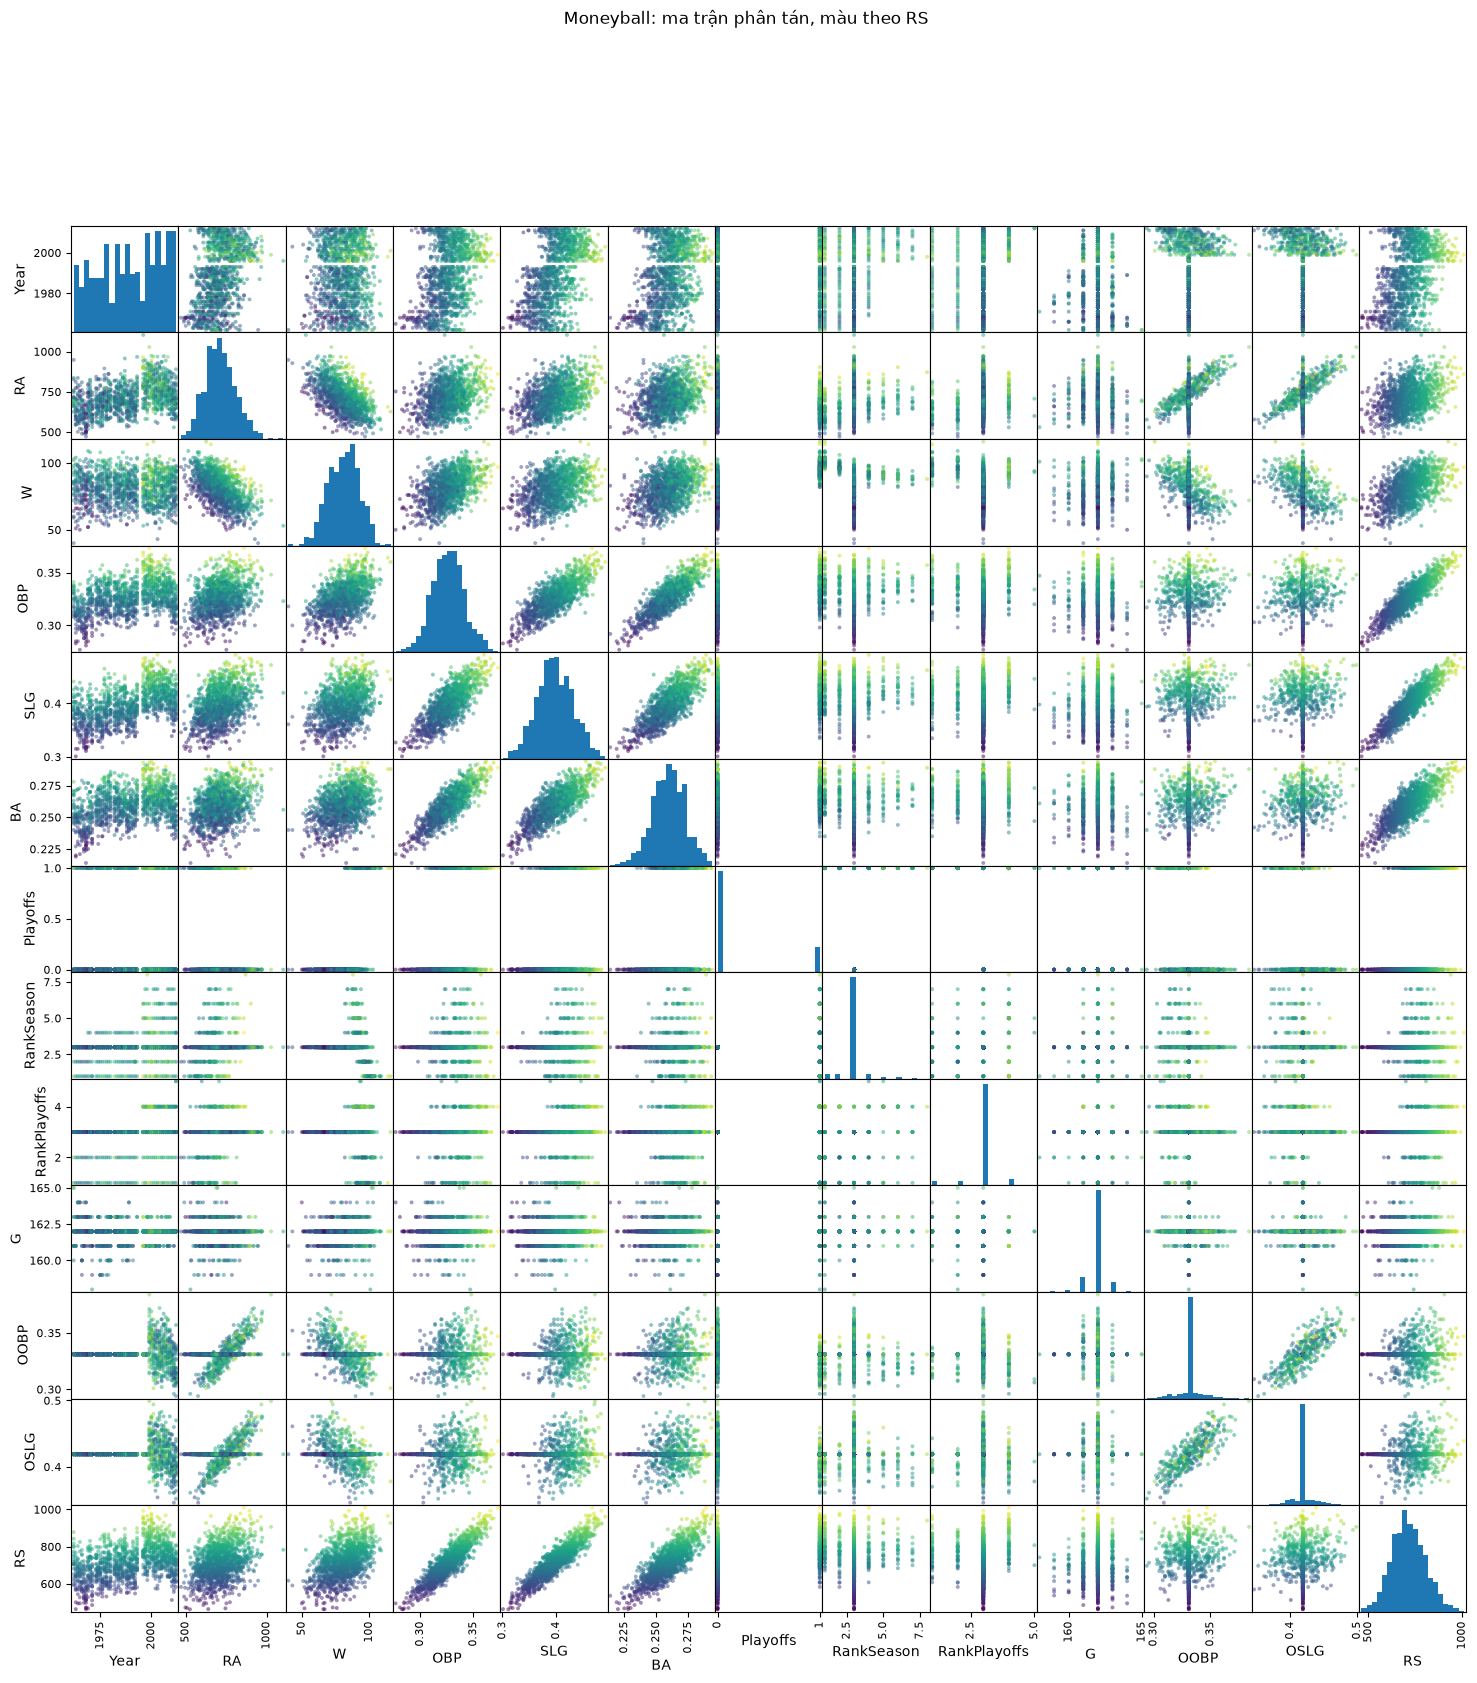

In [4]:
axes = scatter_matrix(visual, c=visual["RS"], figsize=(18, 18), marker="o", s=8,
                      alpha=0.5, cmap="viridis", diagonal="hist", hist_kwds={"bins": 20})
axes[0, 0].figure.suptitle("Moneyball: ma trận phân tán, màu theo RS", y=1.0)
plt.show()

In [5]:
correlations = visual.corr(numeric_only=True)["RS"].drop("RS")
correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index)
display(correlations.to_frame("Pearson r với RS"))

,Pearson r với RS
SLG,0.918740
OBP,0.900492
BA,0.827000
W,0.511745
Year,0.418978
Playoffs,0.386628
RA,0.380139
OSLG,0.110907
OOBP,0.094593
G,0.075195


### So sánh một số mô hình hồi quy tuyến tính

Chia 80/20, `random_state=42`. Mỗi pipeline học trung vị và phép chuẩn hóa **trên train**, sau đó áp dụng vào test. R² càng cao và MAE càng thấp càng tốt. Các tương quan ở trên chỉ là quan hệ thống kê, không chứng minh nguyên nhân.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X_moneyball, y_moneyball, test_size=0.2, random_state=42
)
results = []
for name, estimator in [
    ("LinearRegression", LinearRegression()),
    ("Ridge", Ridge(alpha=1.0)),
    ("Lasso", Lasso(alpha=1.0, max_iter=10000)),
]:
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), estimator)
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)
    results.append({"Mô hình": name, "R² test": r2_score(y_test, prediction),
                    "MAE test": mean_absolute_error(y_test, prediction)})
display(pd.DataFrame(results).round(4))

,Mô hình,R² test,MAE test
0,LinearRegression,0.9397,17.7726
1,Ridge,0.9398,17.7725
2,Lasso,0.9401,17.7790


## II. Bài tập: Netflix 2019

CSV lấy từ [liên kết Google Drive trong đề](https://drive.google.com/file/d/1iH0IU8ybFahoQTTf6A-Ipo6btOj44D1M/view?usp=sharing) và được lưu trong `datasets/lab4/`. Trên Colab notebook đọc bản sao GitHub Raw.

In [7]:
netflix_paths = [Path("datasets/lab4/netflix_titles_2019.csv"), Path("../datasets/lab4/netflix_titles_2019.csv")]
netflix_path = next((p for p in netflix_paths if p.is_file()), None)
netflix_url = "https://raw.githubusercontent.com/shizziio/uit-DS200.G11.CN2.TTNT/main/datasets/lab4/netflix_titles_2019.csv"
netflix = pd.read_csv(netflix_path if netflix_path else netflix_url)
print("Kích thước:", netflix.shape)
display(netflix.head())

Kích thước: (6234, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


### 1–3. Kiểm tra kiểu dữ liệu và giá trị thiếu

Hiển thị số lượng, tỷ lệ thiếu theo cột và một vài dòng thiếu `director`. Đây là dữ liệu Netflix 2019 gồm 6.234 bản ghi, nên các số lượng có thể đối chiếu trực tiếp với ảnh trong đề.

In [8]:
display(netflix.dtypes.to_frame("dtype"))
missing_summary = pd.DataFrame({
    "Số ô thiếu": netflix.isna().sum(),
    "Tỷ lệ thiếu (%)": (netflix.isna().mean() * 100).round(2),
}).sort_values("Số ô thiếu", ascending=False)
display(missing_summary)
display(netflix.loc[netflix["director"].isna(), ["show_id", "title", "director"]].head())

,dtype
show_id,int64
type,str
title,str
director,str
cast,str
country,str
date_added,str
release_year,int64
rating,str
duration,str


,Số ô thiếu,Tỷ lệ thiếu (%)
director,1969,31.58
cast,570,9.14
country,476,7.64
date_added,11,0.18
rating,10,0.16
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00
duration,0,0.00


,show_id,title,director
1,80117401,Jandino: Whatever it Takes,NaN
2,70234439,Transformers Prime,NaN
3,80058654,Transformers: Robots in Disguise,NaN
5,80163890,Apaches,NaN
8,80117902,Fire Chasers,NaN


### 4. Xử lý missing data

Đề minh họa ba cách: bỏ cột, bỏ dòng, điền bằng mode/giá trị thay thế. Bỏ mọi dòng thiếu `director` sẽ mất 1.969 bản ghi, nên ở kết quả cuối giữ nguyên số dòng và điền `Unknown` cho thông tin văn bản chưa biết; `rating` dùng mode. `duration` không thiếu trong CSV này, nên không cần điền 0 (một giá trị không có ý nghĩa cho thời lượng).

In [9]:
print("Nếu bỏ cột director:", netflix.drop(columns="director").shape)
print("Nếu bỏ các dòng thiếu director:", netflix.dropna(subset=["director"]).shape)
print("Ví dụ lọc dòng director không thiếu:")
display(netflix.loc[netflix["director"].notna(), ["title", "director"]].head())

netflix_clean = netflix.copy()
for column in ["director", "cast", "country", "date_added"]:
    netflix_clean[column] = netflix_clean[column].fillna("Unknown")
rating_mode = netflix_clean["rating"].mode().iat[0]
netflix_clean["rating"] = netflix_clean["rating"].fillna(rating_mode)
print("Rating mode:", rating_mode)
print("Số ô thiếu sau xử lý:", int(netflix_clean.isna().sum().sum()))
display(netflix_clean.head())

Nếu bỏ cột director: (6234, 11)
Nếu bỏ các dòng thiếu director: (4265, 12)
Ví dụ lọc dòng director không thiếu:


,title,director
0,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby"
4,#realityhigh,Fernando Lebrija
6,Automata,Gabe Ibáñez
7,Fabrizio Copano: Solo pienso en mi,"Rodrigo Toro, Francisco Schultz"
9,Good People,Henrik Ruben Genz


Rating mode: TV-MA
Số ô thiếu sau xử lý: 0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,Unknown,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,Unknown,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,Unknown,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


### 5. Phân loại và trực quan hóa `rating`

Đếm số chương trình theo từng nhãn phân loại `rating`, bao gồm 10 nhãn thiếu đã được điền bằng `TV-MA`.

,Số chương trình
rating,
TV-MA,2037
TV-14,1698
TV-PG,701
R,508
PG-13,286
NR,218
PG,184
TV-Y7,169
TV-G,149


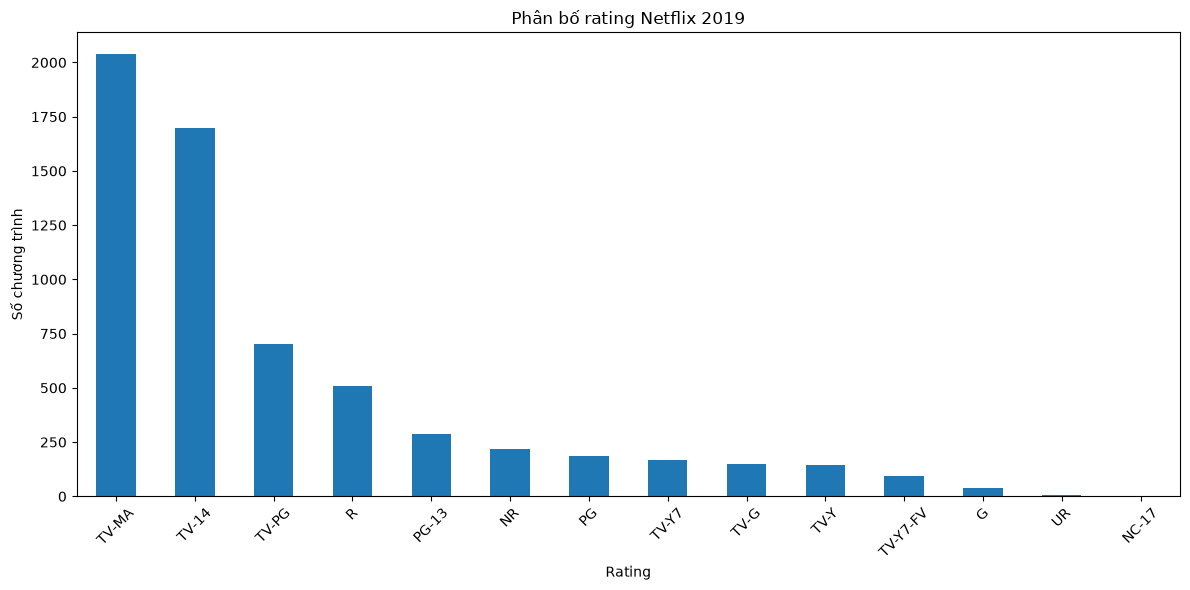

In [10]:
rating_counts = netflix_clean["rating"].value_counts()
display(rating_counts.to_frame("Số chương trình"))
fig, ax = plt.subplots(figsize=(12, 6))
rating_counts.plot.bar(ax=ax)
ax.set(title="Phân bố rating Netflix 2019", xlabel="Rating", ylabel="Số chương trình")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

**Kết luận:** `director` thiếu nhiều nhất (31,58%). Điền mode cho `rating` làm nhóm `TV-MA` tăng từ 2.027 lên 2.037. Với Moneyball, `SLG` và `OBP` có tương quan dương mạnh nhất với `RS` trong các biến đã khảo sát.